In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base_path = "/content/drive/MyDrive/Dataset/New Plant Diseases Dataset(Augmented)"

train_dir = base_path + "/train"
val_dir   = base_path + "/valid"

In [ ]:
import os

print(os.listdir(base_path))   # should show ['train', 'valid']

['train', 'valid']


In [ ]:
!pip install torch torchvision matplotlib seaborn scikit-learn

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [ ]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),   # smaller image
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor()
])

In [ ]:
train_dataset = datasets.ImageFolder(train_dir, transform=transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False)

class_names = train_dataset.classes

print("Classes:", class_names)
print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))

Classes: ['Tomato___Bacterial_spot', 'Tomato___healthy']
Train size: 3628
Validation size: 906


In [ ]:
class FastCNN(nn.Module):
    def __init__(self, num_classes):
        super(FastCNN, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc = nn.Sequential(
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

NameError: name 'nn' is not defined

In [2]:
model = FastCNN(len(class_names)).to(device)
print(model)

NameError: name 'FastCNN' is not defined

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

In [ ]:
train_losses = []
val_losses = []
train_acc = []
val_acc = []

In [ ]:
!pip install tqdm

In [ ]:
from tqdm import tqdm

In [19]:
epochs = 3

for epoch in range(epochs):
    model.train()
    running_loss = 0
    train_correct = 0

    # Progress bar for training batches
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")

    for images, labels in train_bar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()

        # Update description on progress bar
        train_bar.set_postfix(loss=running_loss / (train_bar.n + 1),
                              acc=train_correct / ((train_bar.n + 1) * images.size(0)))

    scheduler.step()

    train_losses.append(running_loss / len(train_loader))
    train_acc.append(train_correct / len(train_dataset))

    # Validation with progress bar
    model.eval()
    val_loss = 0
    val_correct = 0
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]")

    with torch.no_grad():
        for images, labels in val_bar:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()

            val_bar.set_postfix(loss=val_loss / (val_bar.n + 1),
                                acc=val_correct / ((val_bar.n + 1) * images.size(0)))

    val_losses.append(val_loss / len(val_loader))
    val_acc.append(val_correct / len(val_dataset))

    print(f"Epoch {epoch+1}/{epochs} completed: Train Acc={train_acc[-1]:.4f}, Val Acc={val_acc[-1]:.4f}")

Epoch 1/3 [Val]: 100%|██████████| 15/15 [03:58<00:00, 15.88s/it, acc=5.83, loss=0.114]


Epoch 1/3 completed: Train Acc=0.9303, Val Acc=0.9647


Epoch 2/3 [Val]: 100%|██████████| 15/15 [00:06<00:00,  2.36it/s, acc=5.85, loss=0.0905]


Epoch 2/3 completed: Train Acc=0.9537, Val Acc=0.9680


Epoch 3/3 [Val]: 100%|██████████| 15/15 [00:06<00:00,  2.48it/s, acc=5.87, loss=0.0983]

Epoch 3/3 completed: Train Acc=0.9658, Val Acc=0.9713


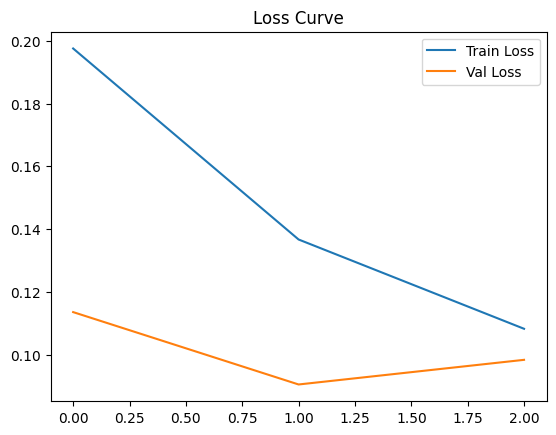

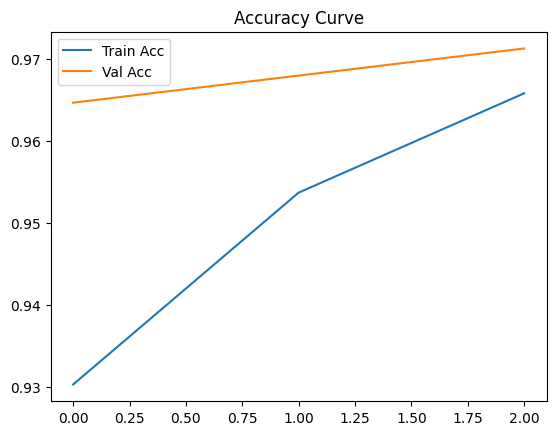

In [20]:
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

plt.plot(train_acc, label="Train Acc")
plt.plot(val_acc, label="Val Acc")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

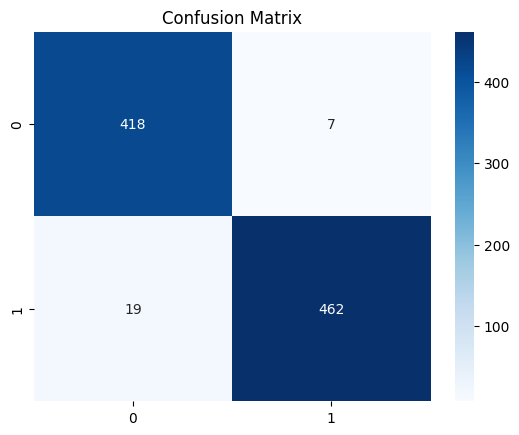

In [21]:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [22]:
print(classification_report(all_labels, all_preds, target_names=class_names))

                         precision    recall  f1-score   support

Tomato___Bacterial_spot       0.96      0.98      0.97       425
       Tomato___healthy       0.99      0.96      0.97       481

               accuracy                           0.97       906
              macro avg       0.97      0.97      0.97       906
           weighted avg       0.97      0.97      0.97       906



In [ ]:
torch.save(model.state_dict(), "/content/plant_model_cpu.pth")

In [24]:
from google.colab import files
files.download("/content/plant_model_cpu.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>